# Tipping bucket rain gauge analysis (Mayfly logger)

**How to use**
1. Put the logger CSV next to this notebook (or give a full path below).
2. Edit the **INPUTS** cell — that's the only cell you need to touch.
3. Run everything: *Kernel → Restart & Run All* (Jupyter) or *Run All* (VS Code / JupyterLab).

Requires `pandas`, `numpy`, `matplotlib`.

In [11]:
# =====================================================================
#  INPUTS — edit this cell only, then Run All
# =====================================================================

# Logger CSV, relative to this notebook or a full path (on Windows use r"C:\path\file.CSV").
# If ONE logger's data is split over several files, a wildcard works: "MAYFLY4_*.CSV"
DATA_FILE = "0928/MAYFLY4_1.CSV"

# Time window to analyse
PERIOD_START = "2026-09-28 11:41"
PERIOD_END   = "2026-09-28 12:20"


---
### Everything below runs automatically — no need to edit

In [12]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

MAX_BARS = 60   # long periods are summed into coarser intervals so the bar chart stays readable

# ---- Gauge constants (same tipping bucket model for the whole group) ---
MM_PER_TIP = 0.2                                        # rain depth per tip (mm)
FUNNEL_DIAM_MM = 200                                    # funnel opening diameter (mm)
ML_PER_TIP = MM_PER_TIP * np.pi * (FUNNEL_DIAM_MM / 2) ** 2 / 1000   # mm³ -> mL (≈ 6.28)

# ---- Load data -------------------------------------------------------
files = sorted(glob.glob(str(DATA_FILE)))
if not files:
    raise FileNotFoundError(
        f"No file matches DATA_FILE = {DATA_FILE!r}.\n"
        f"The notebook is looking in: {Path.cwd()}\n"
        "Check the file name / path in the INPUTS cell."
    )

frames = []
for f in files:
    d = pd.read_csv(f, skipinitialspace=True)
    d.columns = d.columns.str.strip()
    if "Timestamp" not in d.columns:
        raise ValueError(f"{f} has no 'Timestamp' column. Columns found: {list(d.columns)}")
    frames.append(d)

raw = pd.concat(frames, ignore_index=True).drop_duplicates()
raw["Timestamp"] = pd.to_datetime(raw["Timestamp"], errors="coerce")
n_bad = raw["Timestamp"].isna().sum()
if n_bad:
    print(f"⚠ Dropped {n_bad} rows with an unreadable timestamp")

df = (raw.dropna(subset=["Timestamp"])
         .set_index("Timestamp")
         .sort_index()
         .apply(pd.to_numeric, errors="coerce")
         .dropna(how="all"))

tb_cols = [c for c in df.columns if c.startswith("TippingBucket")]
if not tb_cols:
    raise ValueError(f"No 'TippingBucket...' columns found. Columns: {list(df.columns)}")

# Counts go up and down between rows, so they are tips per logging interval (not a running total).
df[tb_cols] = df[tb_cols].fillna(0)

# ---- Check period ----------------------------------------------------
start, end = pd.Timestamp(PERIOD_START), pd.Timestamp(PERIOD_END)
if start >= end:
    raise ValueError(f"PERIOD_START ({start}) must be before PERIOD_END ({end})")
if end < df.index[0] or start > df.index[-1]:
    print(f"⚠ The period ({start} → {end}) is completely outside the data — it will show 0 tips")
elif start < df.index[0] or end > df.index[-1]:
    print("⚠ The period is only partly covered by the data")

step = df.index.to_series().diff().median()
print(f"Files:    {', '.join(files)}")
print(f"Rows:     {len(df)}   ({df.index[0]} → {df.index[-1]}, logging every ~{int(step.total_seconds())} s)")
print(f"Buckets:  {', '.join(tb_cols)}")
print(f"Period:   {start} → {end}")

⚠ The period is only partly covered by the data
Files:    0928/MAYFLY4_1.CSV
Rows:     4274   (2026-09-25 11:35:14 → 2026-09-28 12:19:18, logging every ~61 s)
Buckets:  TippingBucket8_Count
Period:   2026-09-28 11:41:00 → 2026-09-28 12:20:00


### 1. Overview of all logged variables
The shaded area is the period from the INPUTS cell — use this to check it's in the right place.

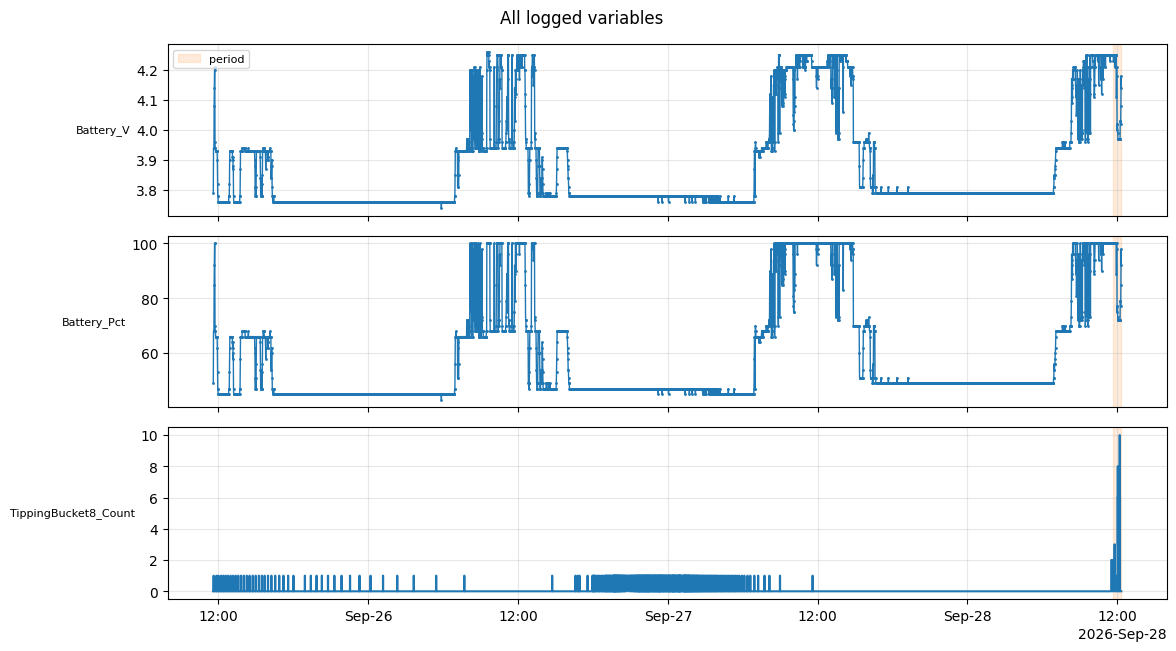

In [13]:
cols = list(df.columns)
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 2.2 * len(cols)), sharex=True, squeeze=False)
axes = axes.ravel()
for ax, col in zip(axes, cols):
    ax.axvspan(start, end, color="C1", alpha=0.15, label="period")
    if col in tb_cols:
        ax.step(df.index, df[col], where="post")      # counts are discrete
    else:
        ax.plot(df.index, df[col], marker=".", ms=2, lw=1)
    ax.set_ylabel(col, rotation=0, ha="right", va="center", fontsize=8)
    ax.grid(alpha=0.3)
axes[0].legend(loc="upper left", fontsize=8)
loc = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(loc)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
fig.suptitle("All logged variables")
fig.tight_layout()
plt.show()

### 2. Cumulative rainfall

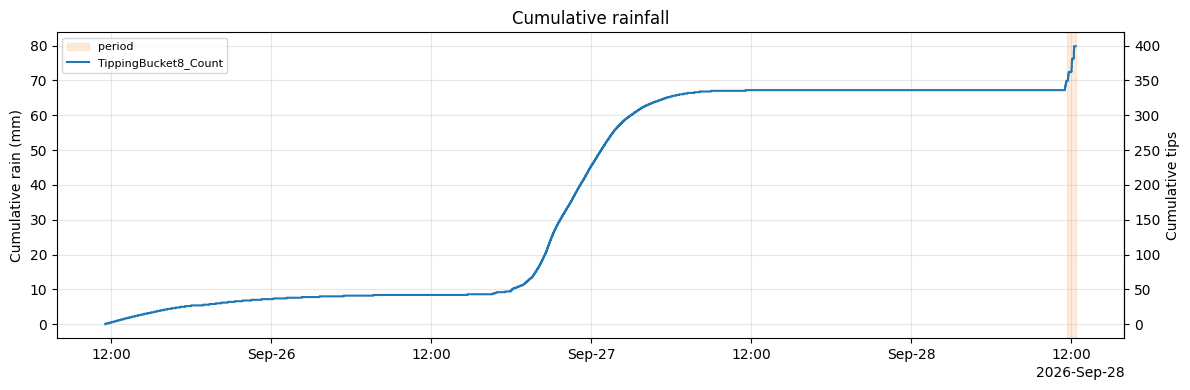

In [14]:
cum_tips = df[tb_cols].cumsum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.axvspan(start, end, color="C1", alpha=0.15, label="period")
for col in tb_cols:
    ax.step(cum_tips.index, cum_tips[col] * MM_PER_TIP, where="post", label=col)
ax.set_ylabel("Cumulative rain (mm)")
sec = ax.secondary_yaxis("right", functions=(lambda mm: mm / MM_PER_TIP, lambda t: t * MM_PER_TIP))
sec.set_ylabel("Cumulative tips")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", fontsize=8)
loc = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(loc)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
ax.set_title("Cumulative rainfall")
fig.tight_layout()
plt.show()

### 3. Totals for the period

In [15]:
tips = df.loc[start:end, tb_cols].sum()
summary = pd.DataFrame({
    "tips": tips.astype(int),
    "rain_mm": tips * MM_PER_TIP,
    "volume_mL": tips * ML_PER_TIP,
})
summary.index.name = "bucket"
if POURED_ML is not None:
    summary["poured_mL"] = POURED_ML
    summary["error_pct"] = (summary["volume_mL"] - POURED_ML) / POURED_ML * 100

display(summary.round({"rain_mm": 2, "volume_mL": 1, "error_pct": 1}))

,tips,rain_mm,volume_mL
bucket,,,
TippingBucket8_Count,50,10.0,314.2


### 5. Volume per interval in the period
Left axis = volume in mL, right axis = the same in tips. Long periods are summed into coarser intervals (shown under the chart).

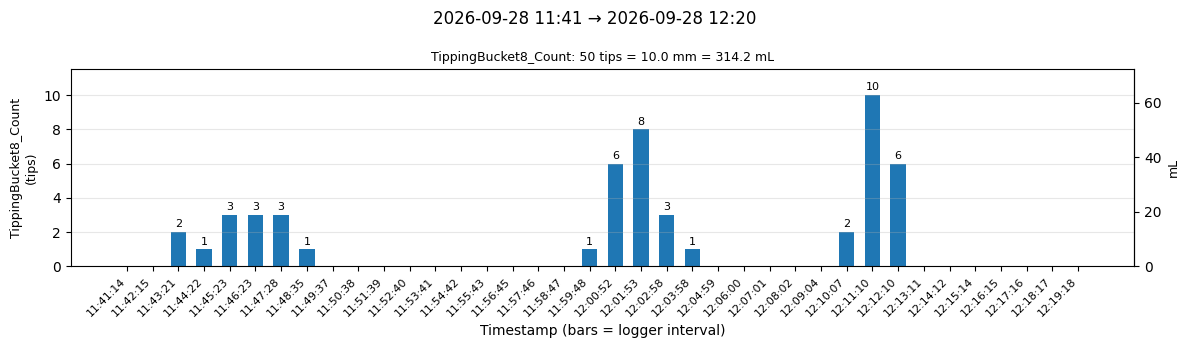

In [16]:
NICE_FREQS = ["1min", "2min", "5min", "10min", "15min", "30min", "1h", "2h", "3h", "6h", "12h", "1D"]

sub = df.loc[start:end, tb_cols]
if sub.empty:
    print("⚠ No data in the period — nothing to plot")
else:
    if len(sub) <= MAX_BARS:
        data, interval = sub, "logger interval"
    else:
        target = (sub.index[-1] - sub.index[0]) / MAX_BARS
        interval = next((f for f in NICE_FREQS if pd.Timedelta(f) >= target), NICE_FREQS[-1])
        data = sub.resample(interval).sum()

    fmt = "%m-%d %H:%M" if (end - start) > pd.Timedelta("1D") else "%H:%M:%S"
    fig, axes = plt.subplots(len(tb_cols), 1, figsize=(12, 3.5 * len(tb_cols)), sharex=True, squeeze=False)
    axes = axes.ravel()
    for ax, col in zip(axes, tb_cols):
        vals = data[col].values
        bars = ax.bar(data.index.strftime(fmt), vals, width=0.6)
        ax.bar_label(bars, labels=[f"{v:g}" if v else "" for v in vals], padding=2, fontsize=8)
        ax.set_ylabel(f"{col}\n(tips)", fontsize=9)
        sec = ax.secondary_yaxis("right", functions=(lambda t: t * ML_PER_TIP, lambda v: v / ML_PER_TIP))
        sec.set_ylabel("mL", fontsize=9)
        ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.grid(axis="y", alpha=0.3)
        ax.margins(y=0.15)
        total = vals.sum()
        ax.set_title(f"{col}: {total:g} tips = {total * MM_PER_TIP:.1f} mm = {total * ML_PER_TIP:.1f} mL", fontsize=9)
    axes[-1].set_xlabel(f"Timestamp (bars = {interval})")
    plt.setp(axes[-1].get_xticklabels(), rotation=45, ha="right", fontsize=8)
    title = f"{start:%Y-%m-%d %H:%M} → {end:%Y-%m-%d %H:%M}"
    if POURED_ML is not None:
        title += f"   (poured {POURED_ML} mL)"
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### 5. Volume per interval in the period

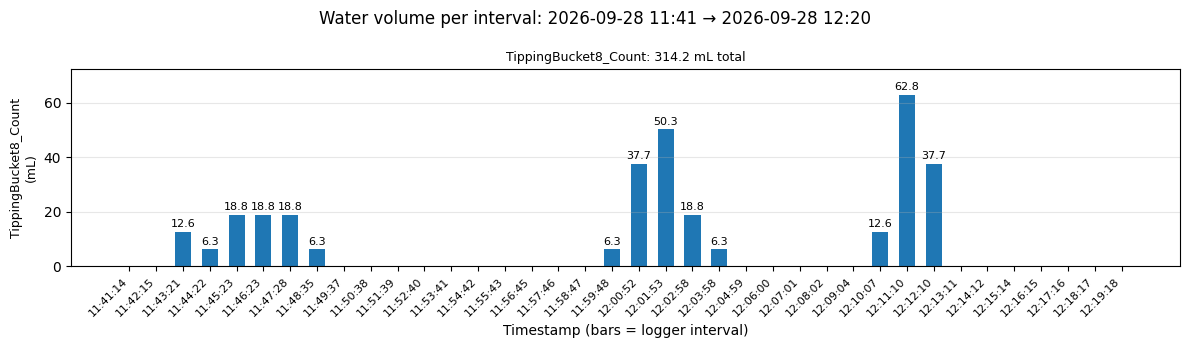

In [17]:
# ---- Volume per interval (mL on the bars) ----
if sub.empty:
    print("⚠ No data in the period — nothing to plot")
else:
    data_ml = data * ML_PER_TIP

    fig, axes = plt.subplots(len(tb_cols), 1, figsize=(12, 3.5 * len(tb_cols)), sharex=True, squeeze=False)
    axes = axes.ravel()
    for ax, col in zip(axes, tb_cols):
        vals = data_ml[col].values
        bars = ax.bar(data_ml.index.strftime(fmt), vals, width=0.6)
        ax.bar_label(bars, labels=[f"{v:.1f}" if v else "" for v in vals], padding=2, fontsize=8)
        ax.set_ylabel(f"{col}\n(mL)", fontsize=9)
        ax.grid(axis="y", alpha=0.3)
        ax.margins(y=0.15)
        ax.set_title(f"{col}: {vals.sum():.1f} mL total", fontsize=9)
    axes[-1].set_xlabel(f"Timestamp (bars = {interval})")
    plt.setp(axes[-1].get_xticklabels(), rotation=45, ha="right", fontsize=8)
    title = f"Water volume per interval: {start:%Y-%m-%d %H:%M} → {end:%Y-%m-%d %H:%M}"
    if POURED_ML is not None:
        title += f"   (poured {POURED_ML} mL)"
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()